# Lab · Pretraining de un GPT (de verdad)

**KEEPCODING · AI Engineering · Clase 2 · Módulo M11: Pretraining**

En **M10** construiste un mini-GPT **a mano**, a nivel de **carácter**, sobre poco texto.
Aquí damos el salto a cómo se hace **de verdad**: un **tokenizer BPE**, más escala,
y entendemos **scaling laws** y por qué los modelos reales **cuestan millones**.
Mismo hilo: **Star Wars**.

> **Cómo seguir este lab**
>
> - Pensado para **Colab con GPU (T4)**. En CPU funciona pero el entrenamiento va lento.
> - Ejecuta en orden. No re-derivamos la arquitectura (eso fue M10): aquí el foco es **datos, tokenizer, escala y coste**.

## 0. Setup

In [1]:
!pip install tokenizers -qU
import math, time, urllib.request
import torch, torch.nn as nn, torch.nn.functional as F
import matplotlib.pyplot as plt
torch.manual_seed(1337)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
CORPUS_URL = 'https://gist.githubusercontent.com/ericrisco/0fb858a1cef9083a0c77954a691caf7d/raw/star_wars_big.txt'
print('PyTorch', torch.__version__, '| device:', device)

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 103.9 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
transformers 5.0.0 requires tokenizers<=0.23.0,>=0.22.0, but you have tokenizers 0.23.1 which is incompatible.
PyTorch 2.11.0+cu128 | device: cuda


## 1. El corpus

Un corpus Star Wars más grande (~8 MB: Wookieepedia + guiones). Aviso de escala: un modelo real se
entrena con **billones** de palabras (todo internet); aquí ~8 MB para **ver el pipeline**, no para igualar a GPT.

In [2]:
try:
    req = urllib.request.Request(CORPUS_URL, headers={'User-Agent':'kc-ai-lab/1.0'})
    texto = urllib.request.urlopen(req, timeout=60).read().decode('utf-8')
except Exception as e:
    raise RuntimeError('No pude descargar el corpus. Comprueba que star_wars_big.txt esté en el gist (CORPUS_URL).') from e
print(f'Corpus: {len(texto):,} caracteres (~{len(texto)/1e6:.2f} MB)')

Corpus: 7,936,090 caracteres (~7.94 MB)


## 2. De carácter a sub-palabra: por qué BPE

_← Slide: "Tokenización (BPE)"._

En M10 cada token era **un carácter**. Funciona, pero **no escala**: una frase son muchísimos tokens
y el modelo gasta su contexto en letras. Los modelos reales usan **sub-palabras** con **BPE**
(Byte-Pair Encoding): empieza por caracteres y **va fusionando los pares más frecuentes** en piezas
más grandes (`f`+`u` → `fu`, `fu`+`e` → `fue`...). Resultado: **muchos menos tokens** por texto.

In [3]:
# Mini-BPE a mano para ver la idea: fusionar el par mas frecuente, repetir.
from collections import Counter
corpus_toy = 'fuerza fuerza fuerte fuego fuerza fuerte fuego'.split()
words = {' '.join(w)+' </w>': c for w,c in Counter(corpus_toy).items()}
def best_pair(words):
    pairs = Counter()
    for w,freq in words.items():
        s = w.split()
        for a,b in zip(s, s[1:]): pairs[(a,b)] += freq
    return pairs.most_common(1)[0][0] if pairs else None
def merge(words, pair):
    bg, rep = ' '.join(pair), ''.join(pair)
    return {w.replace(bg, rep): c for w,c in words.items()}
print('inicio :', list(words.keys()))
for step in range(4):
    bp = best_pair(words)
    words = merge(words, bp)
    print(f'merge {step+1}: {bp} -> {chr(39)}{chr(39).join(bp)}{chr(39)}   ahora: {list(words.keys())}')

inicio : ['f u e r z a </w>', 'f u e r t e </w>', 'f u e g o </w>']
merge 1: ('f', 'u') -> 'f'u'   ahora: ['fu e r z a </w>', 'fu e r t e </w>', 'fu e g o </w>']
merge 2: ('fu', 'e') -> 'fu'e'   ahora: ['fue r z a </w>', 'fue r t e </w>', 'fue g o </w>']
merge 3: ('fue', 'r') -> 'fue'r'   ahora: ['fuer z a </w>', 'fuer t e </w>', 'fue g o </w>']
merge 4: ('fuer', 'z') -> 'fuer'z'   ahora: ['fuerz a </w>', 'fuer t e </w>', 'fue g o </w>']


## 3. Entrenar un tokenizer BPE real

Usamos la librería `tokenizers` para entrenar un BPE sobre TODO el corpus Star Wars.
Vocabulario pequeño (4.000) para el lab; GPT-2/3 usan ~50.000.

In [4]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders

tok = Tokenizer(models.BPE(unk_token='[UNK]'))
tok.pre_tokenizer = pre_tokenizers.ByteLevel(add_prefix_space=True)
tok.decoder = decoders.ByteLevel()
trainer = trainers.BpeTrainer(vocab_size=4000, special_tokens=['[UNK]'])
tok.train_from_iterator([texto], trainer)
vocab_size = tok.get_vocab_size()

print('vocab BPE:', vocab_size)

vocab BPE: 4000


In [5]:
# Checkpoint: cuantos tokens ahorra BPE frente a char-level
frase = 'Luke uses the Force against the Empire, and luke Im your father'
ids = tok.encode(frase).ids
print('frase     :', frase)
print('BPE tokens:', tok.encode(frase).tokens)
print(f'caracteres: {len(frase)}   |   tokens BPE: {len(ids)}   ->  ~{len(frase)/len(ids):.1f}x menos')

frase     : Luke uses the Force against the Empire, and luke Im your father
BPE tokens: ['ĠLuke', 'Ġuses', 'Ġthe', 'ĠForce', 'Ġagainst', 'Ġthe', 'ĠEmpire', ',', 'Ġand', 'Ġl', 'uke', 'ĠIm', 'Ġyour', 'Ġfather']
caracteres: 63   |   tokens BPE: 14   ->  ~4.5x menos


## 4. Tokenizar el corpus y preparar batches

Codificamos todo el corpus con BPE, partimos 90/10 y reusamos el mismo `get_batch` de M10.

In [6]:
ids = tok.encode(texto).ids
datos = torch.tensor(ids, dtype=torch.long)
n = int(0.9*len(datos)); train_data, val_data = datos[:n], datos[n:]
block_size, batch_size = 128, 32
def get_batch(split, bs=batch_size):
    d = train_data if split=='train' else val_data
    ix = torch.randint(len(d)-block_size, (bs,))
    x = torch.stack([d[i:i+block_size] for i in ix])
    y = torch.stack([d[i+1:i+block_size+1] for i in ix])
    return x.to(device), y.to(device)
print(f'tokens totales: {len(datos):,}  (con char-level eran {len(texto):,})')

tokens totales: 2,299,323  (con char-level eran 7,936,090)


## 5. El modelo: el MISMO mini-GPT de M10

No re-derivamos nada: es la arquitectura de M10 (atención + MLP + bloques), ahora con **vocab BPE**.
La metemos condensada en una celda.

In [7]:
class Head(nn.Module):
    def __init__(s,ne,hs,bs,dp):
        super().__init__(); s.k=nn.Linear(ne,hs,bias=False); s.q=nn.Linear(ne,hs,bias=False); s.v=nn.Linear(ne,hs,bias=False)
        s.register_buffer('tril',torch.tril(torch.ones(bs,bs))); s.do=nn.Dropout(dp)
    def forward(s,x):
        B,T,C=x.shape; k,q,v=s.k(x),s.q(x),s.v(x)
        a=q@k.transpose(-2,-1)*C**-0.5
        a=a.masked_fill(s.tril[:T,:T]==0,float('-inf')); a=s.do(F.softmax(a,-1))
        return a@v
class MHA(nn.Module):
    def __init__(s,ne,nh,bs,dp):
        super().__init__(); hs=ne//nh
        s.heads=nn.ModuleList([Head(ne,hs,bs,dp) for _ in range(nh)]); s.proj=nn.Linear(ne,ne); s.do=nn.Dropout(dp)
    def forward(s,x): return s.do(s.proj(torch.cat([h(x) for h in s.heads],-1)))
class FF(nn.Module):
    def __init__(s,ne,dp): super().__init__(); s.net=nn.Sequential(nn.Linear(ne,4*ne),nn.ReLU(),nn.Linear(4*ne,ne),nn.Dropout(dp))
    def forward(s,x): return s.net(x)
class Block(nn.Module):
    def __init__(s,ne,nh,bs,dp): super().__init__(); s.sa=MHA(ne,nh,bs,dp); s.ff=FF(ne,dp); s.l1=nn.LayerNorm(ne); s.l2=nn.LayerNorm(ne)
    def forward(s,x): x=x+s.sa(s.l1(x)); return x+s.ff(s.l2(x))
class MiniGPT(nn.Module):
    def __init__(s,vs,ne,nh,nl,bs,dp=0.1):
        super().__init__(); s.bs=bs; s.te=nn.Embedding(vs,ne); s.pe=nn.Embedding(bs,ne)
        s.blocks=nn.Sequential(*[Block(ne,nh,bs,dp) for _ in range(nl)]); s.lnf=nn.LayerNorm(ne); s.head=nn.Linear(ne,vs)
    def forward(s,idx,targets=None):
        B,T=idx.shape; x=s.te(idx)+s.pe(torch.arange(T,device=idx.device)); x=s.lnf(s.blocks(x)); logits=s.head(x)
        if targets is None: return logits,None
        return logits, F.cross_entropy(logits.view(B*T,-1),targets.view(B*T))
    @torch.no_grad()
    def generate(s,idx,n,temp=1.0):
        s.eval()
        for _ in range(n):
            l,_=s(idx[:,-s.bs:]); l=l[:,-1,:]/max(temp,1e-8)
            idx=torch.cat((idx,torch.multinomial(F.softmax(l,-1),1)),1)
        return idx
print('MiniGPT (BPE) listo.')

MiniGPT (BPE) listo.


## 6. Pretraining (a pequeña escala)

Entrenamos un modelo y vemos la loss bajar. Es el mismo bucle de M10; lo nuevo es que
trabajamos sobre **tokens BPE**.

In [8]:
def entrenar(modelo, iters=500, lr=3e-3, log=250):
    opt=torch.optim.AdamW(modelo.parameters(),lr=lr); hist=[]; t0=time.time()
    @torch.no_grad()
    def val_loss():
        modelo.eval(); L=torch.zeros(50)
        for k in range(50): xb,yb=get_batch('val'); _,l=modelo(xb,yb); L[k]=l.item()
        modelo.train(); return L.mean().item()
    for it in range(iters):
        if it%log==0 or it==iters-1:
            vl=val_loss(); hist.append((it,vl)); print(f'iter {it:4} | val {vl:.3f} | {time.time()-t0:5.1f}s')
        xb,yb=get_batch('train'); _,loss=modelo(xb,yb)
        opt.zero_grad(set_to_none=True); loss.backward(); opt.step()
    return hist

modelo = MiniGPT(vocab_size, ne=256, nh=8, nl=4, bs=block_size).to(device)
print('params:', f'{sum(p.numel() for p in modelo.parameters()):,}')
hist = entrenar(modelo, iters=1200)   # <10 min en T4

params: 5,241,248
iter    0 | val 8.457 |   1.2s
iter  250 | val 5.774 |  13.3s
iter  500 | val 5.597 |  25.6s
iter  750 | val 5.470 |  37.5s
iter 1000 | val 5.446 |  49.3s
iter 1199 | val 5.393 |  58.9s


In [16]:
start = torch.tensor([tok.encode('Luke').ids], device=device)
print(tok.decode(modelo.generate(start, 120, temp=0.8)[0].tolist()))

 Luke Skywalker, published.
*17 &ndash; The High Republic Adventures - The High Republic Vol. 2: Escape 1 published.
*29 &ndash; Darth Vader (2020) 2 published.
*?? &ndash; Star Wars: Beraries published.
*16 &ndash; Star Wars Adventures: The Empire Strikes Back: The Official Star Wars Story published.
*25 &ndash; Darth Vader and the Empire published.
*25 &ndash; Star Wars Insider 2: The Official Star Wars Story published.
*25 &ndash; Rebellion 2 published.
*30


## 7. Scaling laws · más grande = menos loss

_← Slide: "2017 → 2026 / scaling"._

La gran lección del pretraining: la loss **baja de forma predecible** al subir parámetros, datos y cómputo.
Vamos a **verlo**: entrenamos 3 modelos de tamaño creciente unos pocos pasos y comparamos su loss final.

iter    0 | val 8.454 |   0.3s
iter  249 | val 6.352 |   4.4s
  n_embd=64: 0.62M params -> val loss 6.352
iter    0 | val 8.459 |   0.3s
iter  249 | val 6.115 |   5.7s
  n_embd=128: 1.64M params -> val loss 6.115
iter    0 | val 8.465 |   0.7s
iter  249 | val 5.883 |  12.5s
  n_embd=256: 5.24M params -> val loss 5.883


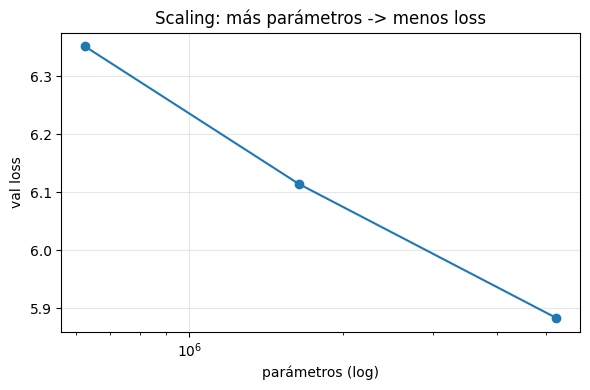

In [10]:
import torch._dynamo  # noqa
sizes = [(64,4,2),(128,4,3),(256,8,4)]   # (n_embd, n_head, n_layer)
res=[]
for ne,nh,nl in sizes:
    m = MiniGPT(vocab_size, ne, nh, nl, block_size).to(device)
    p = sum(x.numel() for x in m.parameters())
    h = entrenar(m, iters=250, log=250)
    res.append((p, h[-1][1]))
    print(f'  n_embd={ne}: {p/1e6:.2f}M params -> val loss {h[-1][1]:.3f}')

ps=[r[0] for r in res]; ls=[r[1] for r in res]
plt.figure(figsize=(6,4)); plt.plot(ps, ls, 'o-')
plt.xscale('log'); plt.xlabel('parámetros (log)'); plt.ylabel('val loss')
plt.title('Scaling: más parámetros -> menos loss'); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

**Chinchilla (DeepMind, 2022)**: para un cómputo dado, lo óptimo es ~**20 tokens de entrenamiento por parámetro**.
GPT-3 estaba *infraentrenado* según esto. La lección práctica: **no basta con modelos grandes, necesitas datos proporcionales**.

## 8. El coste real · por qué no entrenas GPT-3 en casa

_← Slide: "GPT-3 en números"._ Nuestro modelo entrena en minutos. Extrapola eso a escala real:

In [11]:
print(f"{'Modelo':<10}{'Parámetros':>14}{'Tokens train':>14}   Coste estimado")
print('-'*72)
filas=[('nuestro','~3M','~0.3M','~minutos en Colab'),
       ('GPT-2','1.5B','~10B','~decenas de miles $'),
       ('GPT-3','175B','300B','~4.6M $ (estimado)'),
       ('GPT-4','~1.8T (MoE)','~13T','~decenas de M $')]
for n,p,t,c in filas: print(f'{n:<10}{p:>14}{t:>14}   {c}')
print('\nGPT-3: ~3640 petaflop/s-días de computo · ~355 años-GPU (V100) si fuera una sola.')
print('Por eso el pretraining lo hacen unos pocos; tu trabajo como AI Engineer es ADAPTAR esos modelos.')

Modelo        Parámetros  Tokens train   Coste estimado
------------------------------------------------------------------------
nuestro              ~3M         ~0.3M   ~minutos en Colab
GPT-2               1.5B          ~10B   ~decenas de miles $
GPT-3               175B          300B   ~4.6M $ (estimado)
GPT-4        ~1.8T (MoE)          ~13T   ~decenas de M $

GPT-3: ~3640 petaflop/s-días de computo · ~355 años-GPU (V100) si fuera una sola.
Por eso el pretraining lo hacen unos pocos; tu trabajo como AI Engineer es ADAPTAR esos modelos.


## 9. De pretraining a modelo útil

Un modelo recién pre-entrenado solo sabe **continuar texto** (como el nuestro). Para que **siga instrucciones**
y sea útil hace falta **adaptarlo**: fine-tuning supervisado, instruct-tuning, RLHF/DPO.
Eso es justo lo que viene en la **Clase 3 (Adaptación · pesos)**.

## 10. Recap

- **BPE** convierte texto en sub-palabras: muchos menos tokens que char-level → escala.
- El **modelo es el mismo de M10**; lo que cambia en pretraining es **datos + tokenizer + escala**.
- **Scaling laws**: más params/datos/cómputo → menos loss, de forma predecible (Chinchilla: ~20 tokens/param).
- El **coste** del pretraining a escala real es de millones → por eso adaptamos modelos existentes (Clase 3+).